# **COMP3010 Machine Learning Assignment**
This assignment focuses on predicting the peak pressure genretaed by Boiling Liquid Expanding Explosions using machine learning models.

**1. Install Packages**

Below libraries use for data preprocessign,visualization,feature engineering,model development and evaluation

In [54]:
!pip install pandas numpy scikit-learn matplotlib seaborn xgboost lightgbm catboost

**2. Imports**

This imports all necessary libraries for data handling,preprocessing,feature selections,machine learning models and evaluatoin metrices

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.svm import SVR
from sklearn.metrics import (r2_score, mean_absolute_percentage_error, mean_absolute_error,
    root_mean_squared_error)
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import cross_val_score
warnings.filterwarnings('ignore')


**3. Upload Dataset**

The training and testing files are uploaded into GoogleColab.

In [56]:
from google.colab import files
uploaded = files.upload()
#read datasets
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

test_ids = test["ID"] #store ids


Saving train.csv to train (1).csv
Saving test.csv to test (1).csv


**4. Clean Column Names**

Whitespace is removed from columns because they can create errors during preprocessing.

In [57]:
#Remove extra spaces
train.colums = train.columns.str.strip()
test.columns = test.columns.str.strip()
print(train.columns.tolist()) #display column names

['ID', 'Tank Failure Pressure (bar)', 'Liquid Ratio (%)', 'Tank Width (m)', 'Tank Length (m)', 'Tank Height (m)', 'BLEVE Height (m)', 'Vapour Height (m)', 'Vapour Temperature (K)', 'Liquid Temperature (K)', 'Obstacle Distance to BLEVE (m)', 'Obstacle Width (m)', 'Obstacle Height (m)', 'Obstacle Thickness (m)', 'Obstacle Angle', 'Status', 'Liquid Critical Pressure (bar)', 'Liquid Boiling Temperature (K)', 'Liquid Critical Temperature (K)', 'Sensor ID', 'Sensor Position Side', 'Sensor Position x', 'Sensor Position y', 'Sensor Position z', 'Target Pressure (bar)']


**5. Basic Dataset Inspection**

Before preprocessing, inspect the structure of the dataset like checking dataset size,data types ,available features and summary statistics.


In [58]:
#dispaly shape of datasets
print("Train shape:",train.shape)
print("Test shape: " ,test.shape)
train.head() #display first few rows

print("Train Information:\n")
train.info() #display dataset info
train.describe() #display statistical summary

Train shape: (10050, 25)
Test shape:  (3203, 24)
Train Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10050 entries, 0 to 10049
Data columns (total 25 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   ID                               10045 non-null  float64
 1   Tank Failure Pressure (bar)      10043 non-null  float64
 2   Liquid Ratio (%)                 10041 non-null  float64
 3   Tank Width (m)                   10041 non-null  float64
 4   Tank Length (m)                  10041 non-null  float64
 5   Tank Height (m)                  10042 non-null  float64
 6   BLEVE Height (m)                 10040 non-null  float64
 7   Vapour Height (m)                10041 non-null  float64
 8   Vapour Temperature (K)           10022 non-null  float64
 9   Liquid Temperature (K)           10023 non-null  float64
 10  Obstacle Distance to BLEVE (m)   10042 non-null  float64
 11  Obstacle Wi

,ID,Tank Failure Pressure (bar),Liquid Ratio (%),Tank Width (m),Tank Length (m),Tank Height (m),BLEVE Height (m),Vapour Height (m),Vapour Temperature (K),Liquid Temperature (K),...,Obstacle Angle,Liquid Critical Pressure (bar),Liquid Boiling Temperature (K),Liquid Critical Temperature (K),Sensor ID,Sensor Position Side,Sensor Position x,Sensor Position y,Sensor Position z,Target Pressure (bar)
count,10045.000000,10043.000000,10041.000000,10041.000000,10041.000000,10042.000000,10040.000000,10041.000000,10022.000000,10023.000000,...,10042.000000,10020.000000,10021.000000,10020.000000,10042.000000,10042.000000,10043.000000,10042.000000,10041.000000,10040.000000
mean,8202.729119,37.899252,0.504288,1.696627,5.599281,1.673800,1.023503,0.845691,396.755388,343.460330,...,14.598686,40.099461,-20.593753,125.542096,14.010655,2.335491,12.906879,2.984879,3.077263,0.360492
std,2885.998522,225.634505,0.228073,0.764937,2.596056,0.751931,0.575464,0.536538,71.876848,35.536412,...,9.237134,2.297916,20.480981,27.625669,7.791718,1.334306,4.158897,4.712319,4.213429,0.495271
min,3203.000000,4.920000,0.100000,0.380000,0.580000,0.380000,-0.020000,0.180000,281.210000,282.950000,...,0.000000,37.900000,-42.000000,96.700000,1.000000,1.000000,5.150000,-9.050000,-2.800000,0.016098
25%,5705.000000,13.730000,0.300000,1.010000,3.380000,1.010000,0.590000,0.400000,336.620000,312.810000,...,6.000000,37.900000,-42.000000,96.700000,7.000000,1.000000,9.300000,-0.200000,-0.600000,0.102211
50%,8206.000000,22.940000,0.510000,1.620000,5.620000,1.610000,1.010000,0.780000,386.725000,342.330000,...,15.000000,37.900000,-1.000000,152.000000,14.000000,2.000000,12.700000,2.800000,2.300000,0.206346
75%,10701.000000,32.190000,0.700000,2.390000,7.810000,2.390000,1.580000,1.200000,441.965000,365.320000,...,22.000000,42.500000,-1.000000,152.000000,21.000000,3.000000,16.250000,6.400000,5.300000,0.413180
max,13202.000000,4995.616406,0.900000,3.020000,10.020000,3.020000,2.020000,2.620000,573.300000,424.600000,...,30.000000,42.500000,-1.000000,152.000000,27.000000,5.000000,23.750000,19.550000,16.700000,9.170477


**6. Check missing values and duplicates**

This check the dataset has missing values or duplicate that may affect model performance.

In [59]:
#check missing values
print("Missing values:")
print(train.isnull().sum())
print("\n")

#checl duplicates rows
print ("Duplicate rows:" , train.duplicated().sum())



Missing values:
ID                                  5
Tank Failure Pressure (bar)         7
Liquid Ratio (%)                    9
Tank Width (m)                      9
Tank Length (m)                     9
Tank Height (m)                     8
BLEVE Height (m)                   10
Vapour Height (m)                   9
Vapour Temperature (K)             28
Liquid Temperature (K)             27
Obstacle Distance to BLEVE (m)      8
Obstacle Width (m)                  6
Obstacle Height (m)                 6
Obstacle Thickness (m)              7
Obstacle Angle                      8
Status                              7
Liquid Critical Pressure (bar)     30
Liquid Boiling Temperature (K)     29
Liquid Critical Temperature (K)    30
Sensor ID                           8
Sensor Position Side                8
Sensor Position x                   7
Sensor Position y                   8
Sensor Position z                   9
Target Pressure (bar)              10
dtype: int64


Duplicate rows: 50


**7. Remove Duplicates,Handling Missing Values and Categorical values**

Duplicate rows are removed and missing numerical value are replcaed utlizing median value.Moreover,missing categorical values are replaced with unknown.

Target varibale is needed for supervised learning.That is the reasone row with missing values are removed.

In [60]:
#Handle Duplicates
train = train.drop_duplicates()
print(train.duplicated().sum())
print("Removed duplicates:",train.shape)

#Handle missing values
numeric_cols = train.select_dtypes(include=np.number).columns

for col in numeric_cols:
  if col != "Target Pressure (bar)":
    median_value = train[col].median() #calculate median value

    #fill missing values in train and test datasets
    train.loc[:, col] = train[col].fillna(median_value)
    test[col]= test[col].fillna(median_value)

#handle categorical columns
train["Status"]=train["Status"].fillna("unknown")
test["Status"]=test["Status"].fillna("unknown")
train["Sensor Position Side"]=train["Sensor Position Side"].fillna("unknown")
test["Sensor Position Side"]=test["Sensor Position Side"].fillna("unknown")

# Remove rows where target variable is missing
train = train.dropna(subset=["Target Pressure (bar)"])
print("Removed missing target values:",train.shape)

#Display Categorical Data
train.select_dtypes(include=['object']).columns


0
Removed duplicates: (10000, 25)
Removed missing target values: (9990, 25)


Index(['Status'], dtype='object')

**8. Correcting Inaccurate Entries**

Standardises text values to improve data consistency before model training becaue categorical values can contain inconsistent fromatting.

In [61]:
#Convert text to lower case and remove whitespace
train["Status"] = train["Status"].str.lower().str.strip()
test["Status"] = test["Status"].str.lower().str.strip()

#fix spelling issues
train["Status"] = train["Status"].replace({
    "subcoled":"subcooled",
    "subcool":"subcooled",
    "superheat":"superheated",
    "saperheated":"superheated"
})

test["Status"] = test["Status"].replace({
    "subcoled":"subcooled",
    "subcool":"subcooled",
    "superheat":"superheated",
    "saperheated":"superheated"
})

#display uniques values
print(train["Status"].unique())

['superheated' 'subcooled']


**9. Outlier Detection**
  
  Outliers can negatively afffect model performance.Hence,used Boxplot to visualize the distribution of numerical features and identify potential outliers.

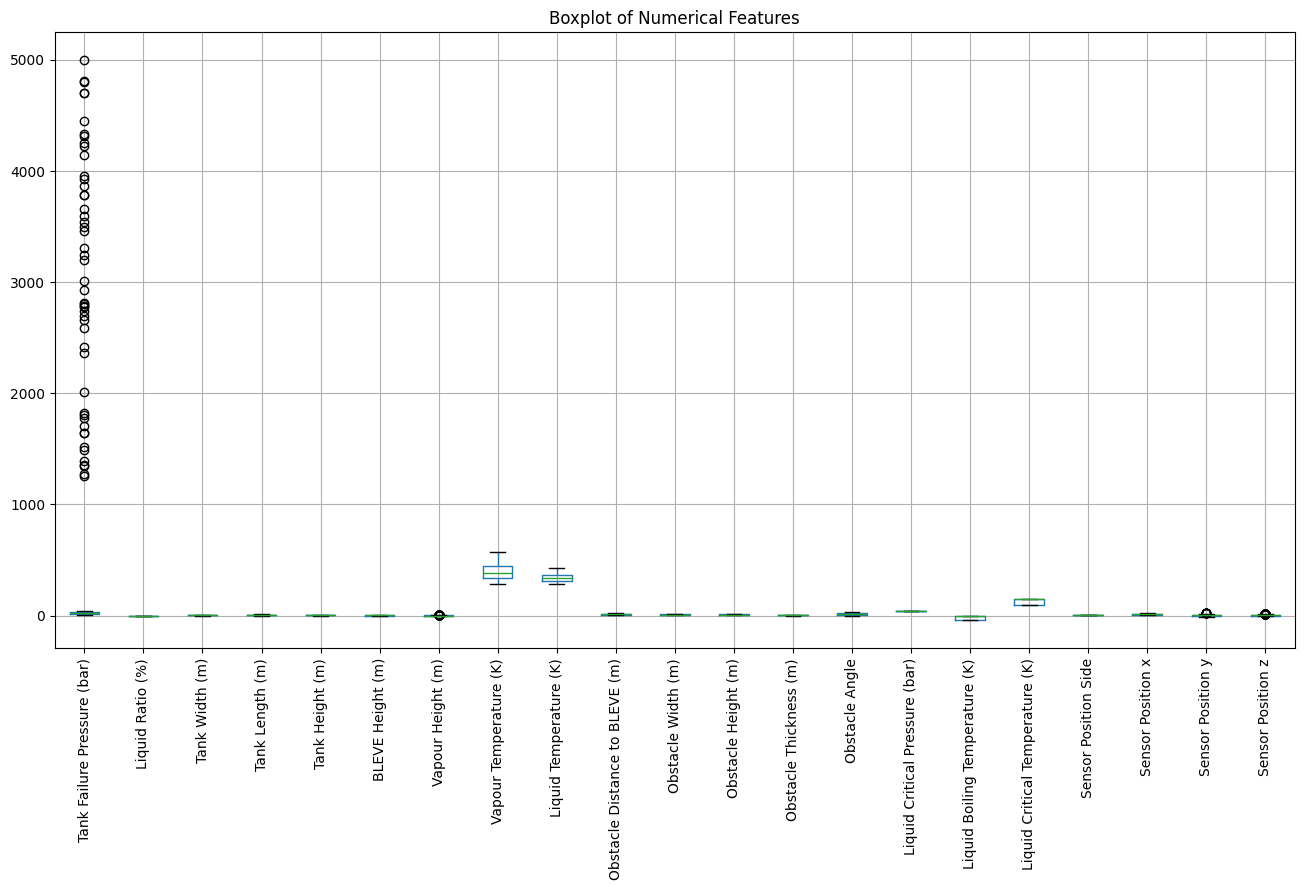

In [62]:
#Select numerical columns
num_cols= train.drop(columns=["Target Pressure (bar)","ID","Sensor ID"]
                     ).select_dtypes(include=np.number).columns
#Boxplot
plt.figure(figsize = (16,8))
train[num_cols].boxplot(rot=90)
plt.title("Boxplot of Numerical Features")
plt.show()




**10. Outlier Treatment**

Outliers are treated using Interquartile Range(IQR) method.

In [63]:
#Treat outliers using IQR capping

for col in num_cols:

    #calculate Q1 and Q3
    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)

    #calculate IQR
    IQR = Q3 - Q1

    lower = Q1 -1.5 *IQR #lower boound
    upper = Q3 +1.5 *IQR #upper bound

    #Apply capping for trainning and testing data
    train [col] = np.where(train[col]< lower,lower,
                                 np.where(train[col] > upper,upper,train[col]))
    test[col] = np.where(test[col] <lower,lower,np.where(test[col] > upper,
                                                         upper,test[col])
    )

print("Outlier treatment completed")

Outlier treatment completed


**11. Feature Engineering**

This is to create additional meaningful features that may improve model performance.Using mathematical relationship between existing varibales,new features are created.

In [64]:
#Tank Volume
train["Tank_Volume"] = (train["Tank Width (m)"] *train["Tank Length (m)"]
                        *train["Tank Height (m)"])
test["Tank_Volume"] = (test["Tank Width (m)"] *test["Tank Length (m)"]
                       *test["Tank Height (m)"])

# Tank surface area
train["Tank_Surface_Area"] =(2 * (
    train["Tank Width (m)"]*train["Tank Length (m)"] +
    train["Tank Width (m)"]* train["Tank Height (m)"] +
    train["Tank Length (m)"]* train["Tank Height (m)"]))

test["Tank_Surface_Area"] = (2 * (
    test["Tank Width (m)"]*test["Tank Length (m)"] +
    test["Tank Width (m)"]*test["Tank Height (m)"] +
    test["Tank Length (m)"]*test["Tank Height (m)"] ))

# Tank ratio
train["Tank_Ratio"] =(train["Tank Width (m)"] /(train["Tank Length (m)"]+1e-5))
test["Tank_Ratio"] =(test["Tank Width (m)"]/(test["Tank Length (m)"] + 1e-5))

# Vapour ratio
train["Vapour_Ratio"] =(train["Vapour Height (m)"] /(train["Tank Height (m)"]
                                                     + 1e-5))
test["Vapour_Ratio"] = (test["Vapour Height (m)"] /(test["Tank Height (m)"]
                                                    + 1e-5))

# Temperature difference
train["Temp_Diff"]=(
    train["Vapour Temperature (K)"]-train["Liquid Temperature (K)"])
test["Temp_Diff"]=(
    test["Vapour Temperature (K)"]-test["Liquid Temperature (K)"])

# Pressure-temperature interaction
train["Pressure_Temp_Interaction"] = (
    train["Tank Failure Pressure (bar)"] *train["Temp_Diff"])
test["Pressure_Temp_Interaction"] = (
    test["Tank Failure Pressure (bar)"] *test["Temp_Diff"])

# Obstacle area
train["Obstacle_Area"] = (
    train["Obstacle Width (m)"] *train["Obstacle Height (m)"])
test["Obstacle_Area"] = (
    test["Obstacle Width (m)"] *test["Obstacle Height (m)"])

# Obstacle volume
train["Obstacle_Volume"] =(train["Obstacle Width (m)"] *
                           train["Obstacle Height (m)"] *
                           train["Obstacle Thickness (m)"])
test["Obstacle_Volume"] =(test["Obstacle Width (m)"] *
                          test["Obstacle Height (m)"] *
                          test["Obstacle Thickness (m)"])

# Distance-height ratio
train["Distance_Height_Ratio"] = (
    train["Obstacle Distance to BLEVE (m)"]/(train["Obstacle Height (m)"]+1e-5))
test["Distance_Height_Ratio"] = (
    test["Obstacle Distance to BLEVE (m)"]/(test["Obstacle Height (m)"]+1e-5))

# Pressure-distance interaction
train["Pressure_Distance_Ratio"] = (train["Tank Failure Pressure (bar)"]/
 (train["Obstacle Distance to BLEVE (m)"] + 1e-5))
test["Pressure_Distance_Ratio"] = (test["Tank Failure Pressure (bar)"] /
 (test["Obstacle Distance to BLEVE (m)"] + 1e-5))

# Sensor distance
train["Sensor_Distance"] = np.sqrt(train["Sensor Position x"]**2 +
                                   train["Sensor Position y"]**2 +
                                   train["Sensor Position z"]**2)
test["Sensor_Distance"] = np.sqrt(test["Sensor Position x"]**2 +
                                  test["Sensor Position y"]**2 +
                                  test["Sensor Position z"]**2)


**12. Seperate Feature(X) and Target(Y)**

Here, target variable is sepreated from the input feature.

In [65]:
y = train["Target Pressure (bar)"]
X = train.drop(columns=["Target Pressure (bar)" , "ID"])

test_ids = test["ID"]
test = test.drop(columns=["ID"])

**13.Data Types Conversion**

Using one-hoe encoding, categorical features are converted into numerical fromat because machine learning models need numerical input data.

Moreover, aligned train and test datasets to make sure they contain the same feature columns.

In [66]:
#convert categorical data using one-hot encoding
X = pd.get_dummies(X, drop_first = True)
test = pd.get_dummies(test,drop_first=True)

#Align train and test columns
X, test = X.align(test,join='left',axis=1,fill_value=0)

# Remove whitespace from feature names for LightGBM
X.columns = X.columns.str.replace(' ', '_')
test.columns = test.columns.str.replace(' ', '_')

**14. Correlation Analysis**

To analyse the relationship between the numerical feature, have used heatmap and it helps to identify related varaibles.

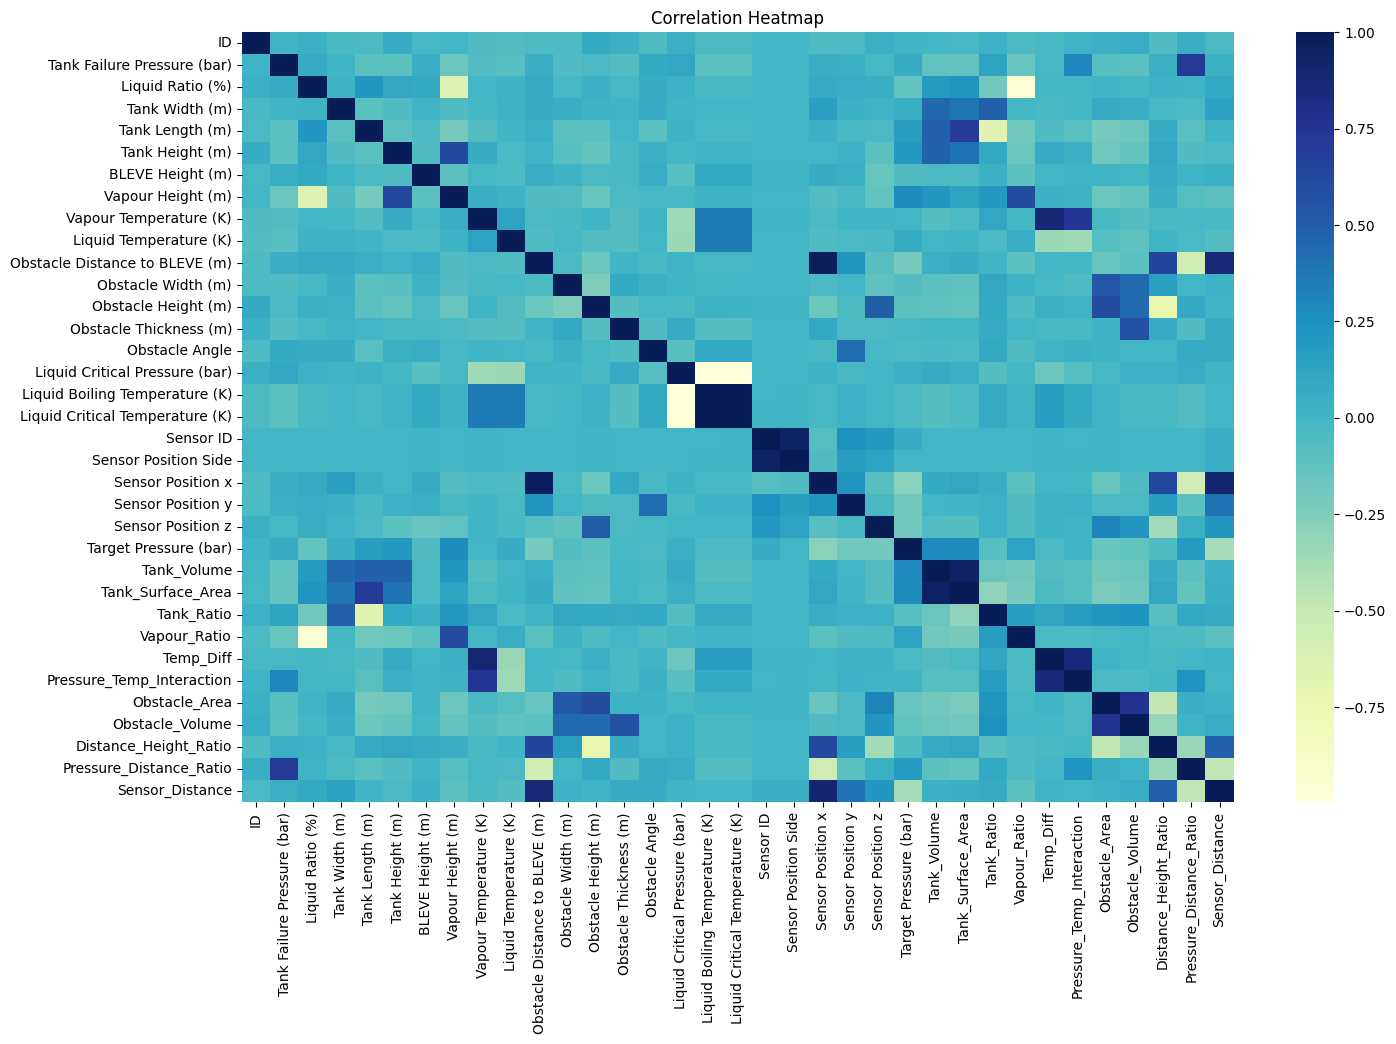

In [67]:
#Create correlation heatmap
plt.figure(figsize=(16,10))
sns.heatmap(
    train.select_dtypes(include=np.number).corr(),
    cmap="YlGnBu"
)
plt.title("Correlation Heatmap")
plt.show()


**15. Train and Split**

Dataset divides into trainning and validation sets. Trainning set for model trainning and validation test for evaluate model performance before testing.

In [68]:
#split dataste into trainning and validation sets
X_train,X_val,y_train,y_val = train_test_split(X,y,test_size=0.15,
                                               random_state=42)
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)

Training set: (8491, 34)
Validation set: (1499, 34)


**16. Feature Selection**

This performs to identify the most important features for predicting the target variable.

In [69]:
#Calculate feature important score
feature_scores = mutual_info_regression(X_train,y_train,random_state=42)
#Create feature importace dataframe
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Score": feature_scores
})
#Sort features by important score
feature_importance = feature_importance.sort_values(by="Score",
                                                    ascending=False)
print (feature_importance)

selected_features = feature_importance.head(60)["Feature"].tolist()

#Keep only selected features
X_train= X_train[selected_features]
X_val= X_val[selected_features]
test= test[selected_features]

print("\nSelected Features:")
print(selected_features)


                            Feature     Score
17                        Sensor_ID  0.507291
18             Sensor_Position_Side  0.450233
19                Sensor_Position_x  0.286440
20                Sensor_Position_y  0.193202
32                  Sensor_Distance  0.186394
23                Tank_Surface_Area  0.148340
30            Distance_Height_Ratio  0.133269
28                    Obstacle_Area  0.127589
31          Pressure_Distance_Ratio  0.126542
22                      Tank_Volume  0.117030
0       Tank_Failure_Pressure_(bar)  0.112804
29                  Obstacle_Volume  0.110456
1                  Liquid_Ratio_(%)  0.107674
7            Vapour_Temperature_(K)  0.106059
26                        Temp_Diff  0.105167
8            Liquid_Temperature_(K)  0.101887
24                       Tank_Ratio  0.098880
27        Pressure_Temp_Interaction  0.096568
9    Obstacle_Distance_to_BLEVE_(m)  0.087570
3                   Tank_Length_(m)  0.084584
6                 Vapour_Height_(m

**17. Feature Scaling**

Feature scaling did using StandardScaler to standardise feature values. Scaling is important for models like SVR.

In [70]:
scaler = StandardScaler()
#Fit scaler on trainning data and transfrom datasets
X_train_scaled= scaler.fit_transform(X_train)
X_val_scaled=scaler.transform(X_val)
test_scaled= scaler.transform(test)
print("Feature scaling completed")


Feature scaling completed


**18. Model 1 -Linear Regression**

Linear Regression models linear relationship between input features and target varable. This was evalueted using r2 Score and Mean Absolute Percentage Error (MAPE) and Root Mean Squared Error(RMSE).

In [71]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled,y_train) #Train model
lr_pred = lr_model.predict(X_val_scaled)#Generate validation predictions

#Evaluate model performance
lr_r2 = r2_score(y_val,lr_pred)
lr_mape = mean_absolute_percentage_error(y_val,lr_pred)
lr_rmse = root_mean_squared_error(y_val,lr_pred)

#Display Results
print("Linear Regression Results")
print("R2 Score:",lr_r2)
print("MAPE:",lr_mape)
print("RMSE:",lr_rmse)



Linear Regression Results
R2 Score: 0.49433265939856885
MAPE: 1.1195270074868835
RMSE: 0.3627672403958244


**19. Model 2 - Support Vector Regression(SVR)**

Support Vector Regression(SVR) uses to model non-linear relationship in dataset. Here, applied RandomizedSearchCV to do hyperparamter tuning and figure out best parameter combination.

In [72]:
#define SVR hyperpaaramter search space
svr_param_grid={
    'C':[1,10,50,100],
    'gamma': ['scale', 0.1, 0.01],
    'kernel': ['rbf']
}

#Randomized hyperparamter search
svr_search = RandomizedSearchCV(estimator=SVR(),
                                param_distributions=svr_param_grid,
                                n_iter=5,
                                scoring='neg_mean_absolute_percentage_error',
                                cv=3,random_state=42,n_jobs=-1)
#Hyperparameter tuning
svr_search.fit(X_train_scaled, y_train)
best_svr = svr_search.best_estimator_
print("Best SVR Parameters:")
print(svr_search.best_params_)

#train tuned model
best_svr.fit(X_train_scaled, y_train)

# Validation prediction
svr_pred = best_svr.predict(X_val_scaled)

# Evaluation
svr_r2 = r2_score(y_val, svr_pred)
svr_mape = mean_absolute_percentage_error(y_val,svr_pred)
svr_rmse = root_mean_squared_error(y_val,svr_pred)
print("\nSVR Results")
print("R2 Score:", svr_r2)
print("MAPE:", svr_mape)
print("RMSE:", svr_rmse)



Best SVR Parameters:
{'kernel': 'rbf', 'gamma': 'scale', 'C': 1}

SVR Results
R2 Score: 0.7637480232177546
MAPE: 0.4400691492403195
RMSE: 0.2479609744475171


**20. Model 3 - LightGBM**

LightGBM is a gradient boosting model use for efficient and high-perfromnce machine learning.

In [73]:
#Initialize LightGBM model
lgbm_model = LGBMRegressor(objective='regression',metric='rmse',
                           boosting_type='gbdt',random_state=42,
                           verbosity=-1,force_col_wise=True)

param_grid={
    'n_estimators':[500, 1000, 1500, 2000],
    'learning_rate': [0.005, 0.01, 0.02],
    'max_depth': [5, 6, 7, 8],
    'num_leaves': [20, 30, 40, 50],
    'subsample': [0.7, 0.8, 0.9],
    'subsample_freq': [1, 5],
    'colsample_bytree': [0.7, 0.8, 0.9],
    'min_child_samples': [5, 10, 20],
    'min_split_gain': [0, 0.01, 0.05],
    'reg_alpha': [0, 0.5, 1],
    'reg_lambda': [1, 3, 5],
    'min_child_weight': [0.001, 0.01, 0.1]
}

#Randomized hyperparameter search
random_search = RandomizedSearchCV(estimator=lgbm_model,
                                   param_distributions=param_grid,
                                   n_iter=30,
                                   scoring='neg_mean_absolute_percentage_error',
                                   cv=3,verbose=1,random_state=42,n_jobs=-1)
#Hyperparameter tuning
random_search.fit(X_train, y_train)
best_lgbm=random_search.best_estimator_
print("Best LightGBM Parameters:")
print(random_search.best_params_)

# Train tuned model
best_lgbm.fit(X_train, y_train)
lgbm_pred = best_lgbm.predict(X_val) #validaiton performance

#Evaluate model performance
lgbm_r2 = r2_score(y_val, lgbm_pred)
lgbm_mape = mean_absolute_percentage_error(y_val,lgbm_pred)
lgbm_rmse = root_mean_squared_error(y_val,lgbm_pred)

print("\nLightGBM Results")
print("R2:", lgbm_r2)
print("MAPE:", lgbm_mape)
print("RMSE:", lgbm_rmse)



Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best LightGBM Parameters:
{'subsample_freq': 5, 'subsample': 0.8, 'reg_lambda': 3, 'reg_alpha': 1, 'num_leaves': 30, 'n_estimators': 2000, 'min_split_gain': 0, 'min_child_weight': 0.1, 'min_child_samples': 20, 'max_depth': 8, 'learning_rate': 0.01, 'colsample_bytree': 0.7}

LightGBM Results
R2: 0.9485485973731768
MAPE: 0.1622807866993359
RMSE: 0.11571621459045658


**21. Model4- CatBoost Model**

CatBoost is a gradient boositing algorithm that performs well on structured tabular datasets.

In [74]:
#Initialize model
cat_model = CatBoostRegressor(verbose=0,random_seed=42)
cat_param_grid = {
    'depth':[6, 8],
    'learning_rate':[0.01, 0.03],
    'iterations':[1000, 1500]
}

#randomized hyperparamter search
cat_search = RandomizedSearchCV(estimator=cat_model,
                                param_distributions=cat_param_grid,
                                n_iter=4,
                                scoring='neg_mean_absolute_percentage_error',
                                cv=3,random_state=42,n_jobs=-1)

cat_search.fit(X_train,y_train) #perform hyperparmeter tuning
best_cat = cat_search.best_estimator_
print("Best CatBoost Paramters:")
print(cat_search.best_params_)

# Train tuned CatBoost
best_cat.fit(X_train, y_train)
cat_pred= best_cat.predict(X_val) #generate validaiton prediction

#Evaluate model performance
cat_r2 = r2_score(y_val, cat_pred)
cat_mape = mean_absolute_percentage_error(y_val,cat_pred)
cat_rmse = root_mean_squared_error(y_val,cat_pred)

print("CatBoost Results")
print("R2:", cat_r2)
print("MAPE:", cat_mape)
print("RMSE:", cat_rmse)


Best CatBoost Paramters:
{'learning_rate': 0.03, 'iterations': 1500, 'depth': 8}
CatBoost Results
R2: 0.9637535333099407
MAPE: 0.1373144546924395
RMSE: 0.09712442212019434


**22. Comparision Table**

Using R2 score ,MAPE and RMSE, model perfromance is compared. This helps to identify the best performing model.

               Model  R2 Score      MAPE      RMSE
0  Linear Regression  0.494333  1.119527  0.362767
1                SVR  0.763748  0.440069  0.247961
2           LightGBM  0.948549  0.162281  0.115716
3           CatBoost  0.963754  0.137314  0.097124


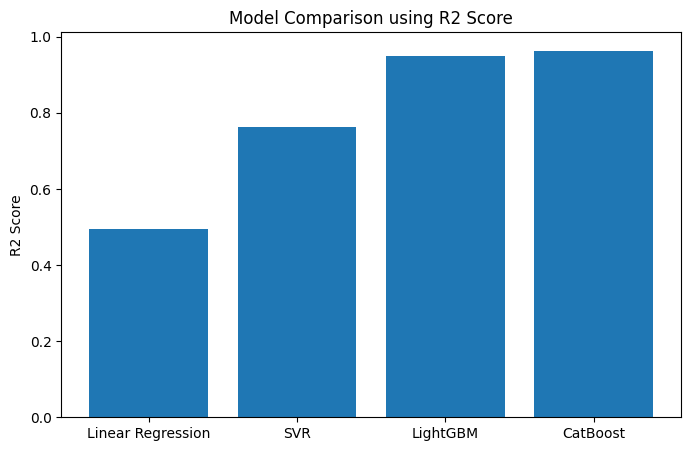

In [75]:
#Create model comparision table
results =pd.DataFrame({
    "Model": ["Linear Regression","SVR","LightGBM","CatBoost"],
    "R2 Score": [lr_r2,svr_r2,lgbm_r2,cat_r2],
    "MAPE": [lr_mape,svr_mape,lgbm_mape,cat_mape],
    "RMSE": [lr_rmse,svr_rmse,lgbm_rmse,cat_rmse]
})
print(results)

#visualize
plt.figure(figsize=(8,5))
plt.bar(results["Model"],results["R2 Score"])
plt.title("Model Comparison using R2 Score")
plt.ylabel("R2 Score")
plt.show()

**23. Cross Validation**
This performs to evaluate the geralization performance of model.A 5-fold cross validation strategy is used with MAPE as the evaluation metric.

In [76]:
#Perform cross validation on LigthGBM model
cv_scores = cross_val_score(best_lgbm,X_train,y_train,cv=5,
                            scoring='neg_mean_absolute_percentage_error')
print("Cross Validation MAPE:")
print(-cv_scores.mean())

Cross Validation MAPE:
0.17117730956864827


**24. Trainning and Validation Performance **

In [77]:
#Function to evaluate model performance
def evaluate_model(name,model,X_train_data,X_val_data):
  #generate trainning and vallidation prediction
  train_pred = model.predict(X_train_data)
  val_pred = model.predict(X_val_data)

  #Calcualte evaluation metrices
  train_mape = mean_absolute_percentage_error(y_train, train_pred)
  val_mape = mean_absolute_percentage_error(y_val, val_pred)
  train_r2 = r2_score(y_train, train_pred)
  val_r2 = r2_score(y_val, val_pred)
  train_rmse = root_mean_squared_error(y_train, train_pred)
  val_rmse = root_mean_squared_error(y_val, val_pred)

  #Return results as dictionary
  return {
        "Model": name,
        "Train MAPE": train_mape,
        "Validation MAPE": val_mape,
        "Train R2": train_r2,
        "Validation R2": val_r2,
        "Train RMSE": train_rmse,
        "Validation RMSE": val_rmse
    }

evaluation_results = []#Store results

#Evalaute models
evaluation_results.append(evaluate_model("Linear Regression",lr_model,
                                           X_train_scaled,X_val_scaled))

evaluation_results.append(evaluate_model("SVR",best_svr,X_train_scaled,
                                           X_val_scaled))
evaluation_results.append(evaluate_model("LightGBM",best_lgbm,X_train,X_val))
evaluation_results.append(evaluate_model("CatBoost",best_cat,X_train,X_val))

evaluation_df = pd.DataFrame(evaluation_results)#Convert results to dataframe
print(evaluation_df)



               Model  Train MAPE  Validation MAPE  Train R2  Validation R2  \
0  Linear Regression    1.185844         1.119527  0.459598       0.494333   
1                SVR    0.416667         0.440069  0.746550       0.763748   
2           LightGBM    0.129329         0.162281  0.981597       0.948549   
3           CatBoost    0.093412         0.137314  0.995833       0.963754   

   Train RMSE  Validation RMSE  
0    0.361704         0.362767  
1    0.247709         0.247961  
2    0.066748         0.115716  
3    0.031763         0.097124  


**25.Final Prediction**

The final predicition are genrated using ensemble of multiple models.Weighted averaging is applied to combine the predictions from CatBoost,LightGBM and SVR model.

In [78]:
#Select final feature set
X_full = X[selected_features]
scaler_final= StandardScaler()

#Scale trainning and testing for SVR
X_full_scaled = scaler_final.fit_transform(X_full)
test_scaled_final = scaler_final.transform(test)

#Train models using full dataset
best_lgbm.fit(X_full, y)
best_cat.fit(X_full, y)
best_svr.fit(X_full_scaled, y)

#Generate prediction
lgbm_test_pred= best_lgbm.predict(test)
cat_test_pred= best_cat.predict(test)
svr_test_pred= best_svr.predict(test_scaled_final)

#Cretae ensemble prediction
final_predictions = (0.60 *cat_test_pred +0.35 *lgbm_test_pred +0.05 *
                     svr_test_pred)
submission=pd.DataFrame({"ID": test_ids,
                           "Target Pressure (bar)": final_predictions})

submission.to_csv("prediction.csv",index=False)
print("Prediction file created successfully")




Prediction file created successfully
